# GP surrogate — an honest look, dimension by dimension

**Read this first — it explains the thing that looked broken.**

A previous version of these plots drew *every* observation on top of each 1-D
curve, and most points sat nowhere near the line. That was a plotting mistake, not
a model failure.

The curve in a slice plot is the surrogate along **one** input while every **other**
input is pinned at a fixed value. An observation only belongs on that curve if its
other coordinates happen to match those pinned values. In eight dimensions
essentially none of them do. So a point drawn at its own `x2` but carrying a `y`
produced by a completely different `x0, x1, x3…` will land far from the line, and
that tells you nothing about fit.

This notebook fixes it three ways:

1. **An in-sample fit check first.** Predicted versus actual at the observed points.
   If the model passes through the data, the slice plots cannot be evidence that it
   does not.
2. **Slice plots that only show points actually near the slice.** Marker opacity
   fades with distance from it, and each panel states how many observations
   qualified. When the answer is zero, that *is* the finding: nothing has been
   measured anywhere near that line.
3. **Partial-dependence plots — the correct "surrogate over each dimension".**
   Instead of pinning the other inputs at one arbitrary setting, the model is
   averaged over many settings of them. Faint lines are the individual settings,
   the bold line is their average. Every observation legitimately belongs on this
   panel, so the raw data is drawn there.

Then, as before: raw marginals, ARD lengthscales, 2-D maps for the two-input
functions, and a leave-one-out honesty check.

Transforms: F1 is modelled on `log10|y|` (its raw values span 120 orders of
magnitude), F5 on `log y`, everything else on the raw output.


In [1]:
import warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
warnings.filterwarnings("ignore")

from bbo_toolkit import fit_gp, expected_improvement

# ---- configuration -------------------------------------------------------
RANDOM_STATE  = 0
XI            = 0.01     # EI exploration margin used for the EI panels
N_GRID        = 200      # resolution of each 1-D curve
N_GRID_2D     = 120      # resolution of the 2-D maps
LOO_RESTARTS  = 2        # kernel restarts during leave-one-out (keep small)
ANCHOR        = "best"   # slice through: "best" or "mean"
NEAR_TOL      = 0.25     # a point is "near the slice" if its RMS distance in the
                         # OTHER dimensions is below this
N_ICE         = 14       # individual settings drawn per dimension

TRANSFORM = {1: "log10abs", 5: "log"}   # None | "log" | "log10abs"

# ---- palette (validated categorical slots 1-3) ---------------------------
MEAN, ACQ, MARK = "#2a78d6", "#1baf7a", "#eb6834"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e2"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "legend.frameon": False,
    "lines.linewidth": 2.0,
})
print("ready")

ready


In [2]:
def load(i):
    Xi = np.load(f"function_{i}/initial_inputs.npy")
    yi = np.load(f"function_{i}/initial_outputs.npy").ravel()
    try:
        df = pd.read_csv(f"function_{i}/new_trials.csv")
        return (np.vstack([Xi, df.iloc[:, :-1].to_numpy(float)]),
                np.concatenate([yi, df.iloc[:, -1].to_numpy(float)]), len(yi))
    except (FileNotFoundError, pd.errors.EmptyDataError):
        return Xi, yi, len(yi)


def transform(i, y):
    t = TRANSFORM.get(i)
    if t == "log":      return np.log(y), "log y"
    if t == "log10abs": return np.log10(np.abs(y)), "log10 |y|"
    return y, "y"


def lengthscales(gp):
    for p, v in gp.kernel_.get_params().items():
        if p.endswith("length_scale") and not p.endswith("bounds"):
            return np.atleast_1d(v).astype(float)


def noise_level(gp):
    for p, v in gp.kernel_.get_params().items():
        if p.endswith("noise_level") and not p.endswith("bounds"):
            return float(v)
    return 0.0


def other_dim_distance(X, anchor, j):
    """RMS distance per dimension, ignoring dimension j."""
    k = [c for c in range(X.shape[1]) if c != j]
    if not k:
        return np.zeros(len(X))
    return np.sqrt(np.mean((X[:, k] - anchor[k]) ** 2, axis=1))
print("ready")

ready


In [3]:
def insample_fit(gp, X, yy, label, title):
    """Does the surrogate pass through its own training data? (It should.)"""
    mu, sd = gp.predict(X, return_std=True)
    r2 = 1 - np.sum((yy - mu) ** 2) / np.sum((yy - yy.mean()) ** 2)
    fig, ax = plt.subplots(figsize=(4.0, 3.7))
    lim = [min(yy.min(), mu.min()), max(yy.max(), mu.max())]
    pad = 0.05 * (lim[1] - lim[0] + 1e-12)
    ax.plot(lim, lim, color=INK2, lw=1.2, ls="--", zorder=1)
    ax.errorbar(yy, mu, yerr=2 * sd, fmt="o", ms=5, color=MEAN, ecolor=MEAN,
                elinewidth=0.8, alpha=0.8, capsize=0, zorder=2)
    ax.set_xlim(lim[0] - pad, lim[1] + pad); ax.set_ylim(lim[0] - pad, lim[1] + pad)
    ax.set_xlabel(f"observed ({label})"); ax.set_ylabel("surrogate prediction")
    ax.set_title(f"{title}\nin-sample R2 = {r2:.4f}  (1.0 = passes through every point)",
                 loc="left")
    plt.tight_layout(); plt.show()
    return r2


def slice_grid(gp, X, yy, anchor, label, title):
    """One input varies, the rest pinned at `anchor`. Only near-slice points shown."""
    d = X.shape[1]
    fig = plt.figure(figsize=(3.2 * d, 5.6))
    gs = GridSpec(2, d, height_ratios=[2.1, 1.0], hspace=0.36, wspace=0.22)
    g = np.linspace(0, 1, N_GRID)
    y_best = float(np.max(gp.predict(X)))

    MU, SD, EI = [], [], []
    for j in range(d):
        P = np.tile(anchor, (N_GRID, 1)); P[:, j] = g
        mu, sd = gp.predict(P, return_std=True)
        MU.append(mu); SD.append(sd)
        EI.append(expected_improvement(P, gp, y_best=y_best, xi=XI))

    lo = min(float(np.min(m - 2 * s)) for m, s in zip(MU, SD))
    hi = max(float(np.max(m + 2 * s)) for m, s in zip(MU, SD))
    pad = 0.06 * (hi - lo + 1e-12)
    ei_hi = max(float(np.max(e)) for e in EI) * 1.08 + 1e-12

    for j in range(d):
        mu, sd, ei = MU[j], SD[j], EI[j]
        dist = other_dim_distance(X, anchor, j)
        near = dist <= NEAR_TOL

        ax = fig.add_subplot(gs[0, j])
        ax.fill_between(g, mu - 2 * sd, mu + 2 * sd, color=MEAN, alpha=0.16, lw=0,
                        label="+/- 2 sd")
        ax.plot(g, mu, color=MEAN, label="surrogate mean")
        if near.any():
            a = 0.85 * (1 - dist[near] / NEAR_TOL) + 0.15
            ax.scatter(X[near, j], yy[near], s=44, color=INK2, lw=0, alpha=a,
                       zorder=3, label=f"observations near this slice")
        ax.plot(anchor[j], yy.max(), marker="o", ms=8, color=MARK, mec="#fcfcfb",
                mew=1.5, zorder=4, label="current best")
        ax.axvline(anchor[j], color=MARK, lw=1.5, ls="--", zorder=2)
        ax.plot(X[:, j], np.full(len(X), lo - pad * 0.55), marker="|", ls="none",
                ms=6, color=INK2, alpha=0.45, zorder=2)
        ax.set_title(f"x{j}   lengthscale {lengthscales(gp)[j]:.3g}\n"
                     f"observations near this slice: {int(near.sum())} of {len(X)}",
                     fontsize=9)
        ax.set_xlim(0, 1); ax.set_ylim(lo - pad, hi + pad)
        if j == 0:
            ax.set_ylabel(label); ax.legend(loc="lower left", fontsize=7)
        else:
            ax.set_yticklabels([])

        axb = fig.add_subplot(gs[1, j])
        axb.fill_between(g, 0, ei, color=ACQ, alpha=0.22, lw=0)
        axb.plot(g, ei, color=ACQ)
        axb.axvline(anchor[j], color=MARK, lw=1.2, ls="--")
        axb.set_xlim(0, 1); axb.set_ylim(0, ei_hi); axb.set_xlabel(f"x{j}")
        if j == 0:
            axb.set_ylabel(f"EI (xi={XI})")
        else:
            axb.set_yticklabels([])

    fig.suptitle(title + "   —   other inputs pinned at the current best",
                 color=INK, fontsize=12, y=0.99, ha="left", x=0.02)
    plt.show()
print("ready")

ready


In [4]:
def partial_dependence(gp, X, yy, label, title):
    """The surrogate averaged over the other inputs, instead of pinning them."""
    rng = np.random.default_rng(RANDOM_STATE)
    d = X.shape[1]
    g = np.linspace(0, 1, N_GRID)
    idx = rng.choice(len(X), size=min(N_ICE, len(X)), replace=False)

    curves = []
    for j in range(d):
        ice = np.empty((len(idx), N_GRID))
        for r, k in enumerate(idx):
            P = np.tile(X[k], (N_GRID, 1)); P[:, j] = g
            ice[r] = gp.predict(P)
        curves.append(ice)

    lo = min(float(c.min()) for c in curves); lo = min(lo, float(yy.min()))
    hi = max(float(c.max()) for c in curves); hi = max(hi, float(yy.max()))
    pad = 0.06 * (hi - lo + 1e-12)

    fig, axes = plt.subplots(1, d, figsize=(3.2 * d, 3.4), squeeze=False)
    for j in range(d):
        ax = axes[0, j]; ice = curves[j]
        for r in range(len(idx)):
            ax.plot(g, ice[r], color=MEAN, lw=0.9, alpha=0.28, zorder=2)
        ax.plot(g, ice.mean(0), color=MEAN, lw=2.6, zorder=4,
                label="average over the other inputs")
        ax.scatter(X[:, j], yy, s=20, color=INK2, alpha=0.55, lw=0, zorder=3,
                   label="all observations")
        ax.set_xlim(0, 1); ax.set_ylim(lo - pad, hi + pad); ax.set_xlabel(f"x{j}")
        if j == 0:
            ax.set_ylabel(label); ax.legend(fontsize=7, loc="best")
        else:
            ax.set_yticklabels([])
    fig.suptitle(title + "   —   partial dependence (the honest per-dimension view)",
                 color=INK, fontsize=12, y=1.05, ha="left", x=0.02)
    plt.tight_layout(); plt.show()
print("ready")

ready


In [5]:
def raw_marginals(X, y, n_init, label, title):
    d = X.shape[1]
    fig, axes = plt.subplots(1, d, figsize=(2.7 * d, 2.6), squeeze=False)
    for j in range(d):
        ax = axes[0, j]
        ax.scatter(X[:n_init, j], y[:n_init], s=20, color=INK2, alpha=0.5, lw=0,
                   label="initial")
        if len(y) > n_init:
            ax.scatter(X[n_init:, j], y[n_init:], s=46, color=MARK, lw=0,
                       label="our trials", zorder=3)
        ax.set_xlabel(f"x{j}"); ax.set_xlim(0, 1)
        if j == 0:
            ax.set_ylabel(label); ax.legend(fontsize=7.5)
    fig.suptitle(title, color=INK, fontsize=11, y=1.06, ha="left", x=0.02)
    plt.tight_layout(); plt.show()


def ard_bars(gp, title):
    ls = lengthscales(gp); d = len(ls)
    fig, ax = plt.subplots(figsize=(1.1 * d + 2.4, 2.4))
    ax.bar(range(d), ls, color=MEAN, width=0.55, zorder=2)
    ax.axhline(10.0, color=MARK, lw=1.4, ls="--")
    ax.text(-0.45, 11.5, "ceiling = model treats this input as irrelevant",
            color=MARK, fontsize=7.5, ha="left")
    ax.set_yscale("log"); ax.set_xticks(range(d))
    ax.set_xticklabels([f"x{j}" for j in range(d)])
    ax.set_ylabel("lengthscale (log)")
    for j, v in enumerate(ls):
        ax.text(j, v * 1.12, f"{v:.3g}", ha="center", fontsize=7.5, color=INK2)
    ax.set_title(title, loc="left")
    plt.tight_layout(); plt.show()


def map_2d(gp, X, yy, title):
    g = np.linspace(0, 1, N_GRID_2D); A, B = np.meshgrid(g, g)
    mu, sd = gp.predict(np.column_stack([A.ravel(), B.ravel()]), return_std=True)
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.1))
    for ax, Z, name, cmap in ((axes[0], mu.reshape(A.shape), "surrogate mean", "Blues"),
                              (axes[1], sd.reshape(A.shape), "uncertainty (sd)", "Oranges")):
        c = ax.contourf(A, B, Z, levels=24, cmap=cmap)
        fig.colorbar(c, ax=ax, fraction=0.046, pad=0.03)
        ax.scatter(X[:, 0], X[:, 1], s=26, color=INK, lw=0.8, edgecolor="#fcfcfb", zorder=3)
        k = int(np.argmax(yy))
        ax.plot(X[k, 0], X[k, 1], marker="*", ms=16, color=MARK, mec="#fcfcfb",
                mew=1.2, zorder=4)
        ax.set_title(name, loc="left"); ax.set_xlabel("x0"); ax.set_ylabel("x1")
        ax.grid(False)
    fig.suptitle(title, color=INK, fontsize=12, y=1.02, ha="left", x=0.02)
    plt.tight_layout(); plt.show()


def loo_check(X, yy, label, title):
    n = len(yy); pred = np.empty(n); sd = np.empty(n)
    for k in range(n):
        m = np.ones(n, bool); m[k] = False
        g = fit_gp(X[m], yy[m], n_restarts_optimizer=LOO_RESTARTS,
                   random_state=RANDOM_STATE)
        p, s = g.predict(X[k].reshape(1, -1), return_std=True)
        pred[k], sd[k] = p[0], s[0]
    q2 = 1 - np.sum((yy - pred) ** 2) / np.sum((yy - yy.mean()) ** 2)
    z = np.mean(np.abs((yy - pred) / np.maximum(sd, 1e-12)))
    fig, ax = plt.subplots(figsize=(4.0, 3.8))
    lim = [min(yy.min(), pred.min()), max(yy.max(), pred.max())]
    pad = 0.05 * (lim[1] - lim[0] + 1e-12)
    ax.plot(lim, lim, color=INK2, lw=1.2, ls="--", zorder=1)
    ax.errorbar(yy, pred, yerr=2 * sd, fmt="o", ms=5, color=MEAN, ecolor=MEAN,
                elinewidth=0.8, alpha=0.75, capsize=0, zorder=2)
    ax.set_xlim(lim[0] - pad, lim[1] + pad); ax.set_ylim(lim[0] - pad, lim[1] + pad)
    ax.set_xlabel(f"actual ({label})"); ax.set_ylabel("predicted, point held out")
    ax.set_title(f"{title}\nQ2 = {q2:.2f}   |   mean |z| = {z:.2f}", loc="left")
    plt.tight_layout(); plt.show()
    return q2
print("ready")

ready


In [6]:
def report(i, do_loo=True):
    X, y, n_init = load(i)
    yy, label = transform(i, y)
    gp = fit_gp(X, yy, random_state=RANDOM_STATE)
    d = X.shape[1]; k = int(np.argmax(yy))
    anchor = X[k] if ANCHOR == "best" else X.mean(0)

    print("=" * 78)
    print(f"FUNCTION {i}   dim={d}   n={len(y)} ({n_init} initial + {len(y)-n_init} trials)")
    print(f"  modelling {label};  best = {yy[k]:.6g}  at  {np.round(X[k], 6)}")
    print(f"  raw best y = {y.max():.6g}")
    print(f"  kernel: {gp.kernel_}")
    ns = np.sqrt(noise_level(gp))
    print(f"  noise sd = {ns:.4g}  vs  output sd = {yy.std():.4g}"
          f"   ->  noise is {100*ns/max(yy.std(),1e-12):.0f}% of the signal")
    print("=" * 78)

    insample_fit(gp, X, yy, label, f"F{i} — does the surrogate fit its own data?")
    slice_grid(gp, X, yy, anchor, label, f"F{i} — conditional slices")
    partial_dependence(gp, X, yy, label, f"F{i}")
    raw_marginals(X, y, n_init, "y (raw)", f"F{i} — raw observations, no model")
    ard_bars(gp, f"F{i} — ARD lengthscales")
    if d == 2:
        map_2d(gp, X, yy, f"F{i} — full surrogate over the square")
    if do_loo:
        loo_check(X, yy, label, f"F{i} — leave-one-out honesty check")
    return gp
print("ready")

ready


## Function 1

FUNCTION 1   dim=2   n=13 (10 initial + 3 trials)
  modelling log10 |y|;  best = -2.44297  at  [0.650114 0.681526]
  raw best y = 7.71088e-16
  kernel: 1.12**2 * Matern(length_scale=[0.202, 0.205], nu=2.5) + WhiteKernel(noise_level=1e-06)
  noise sd = 0.001  vs  output sd = 34.46   ->  noise is 0% of the signal


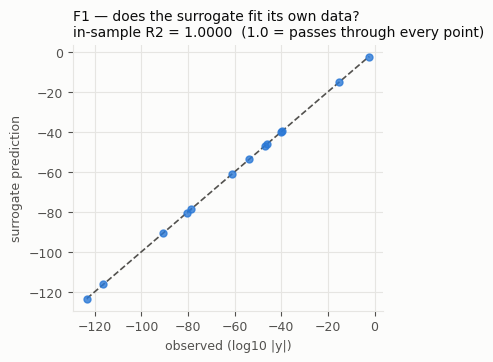

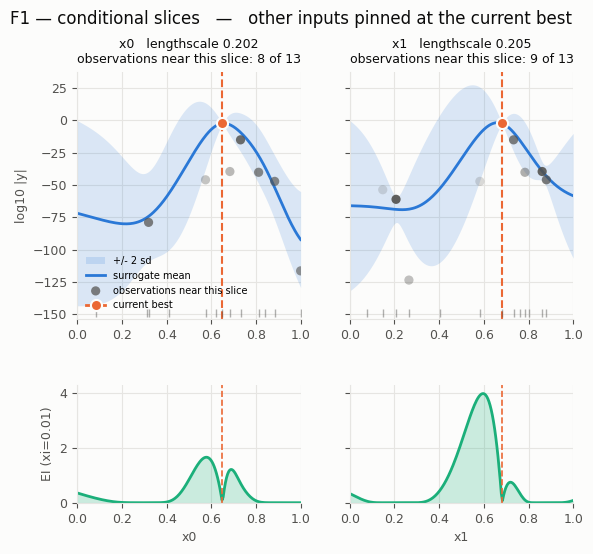

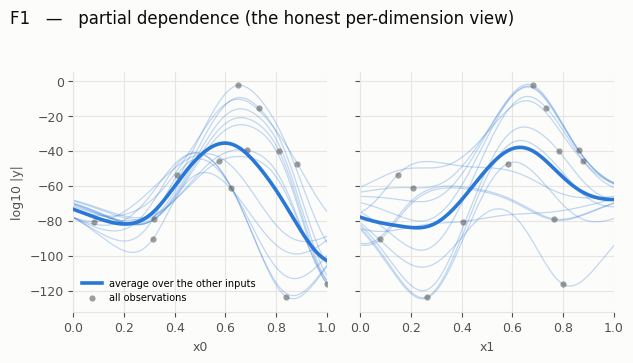

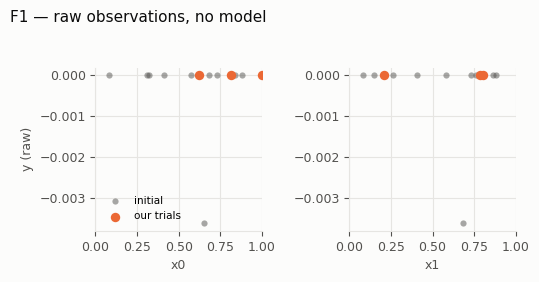

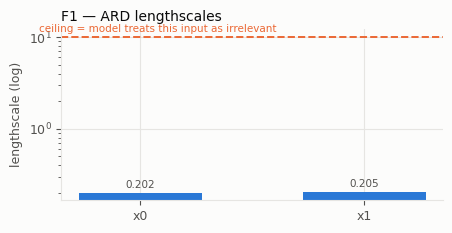

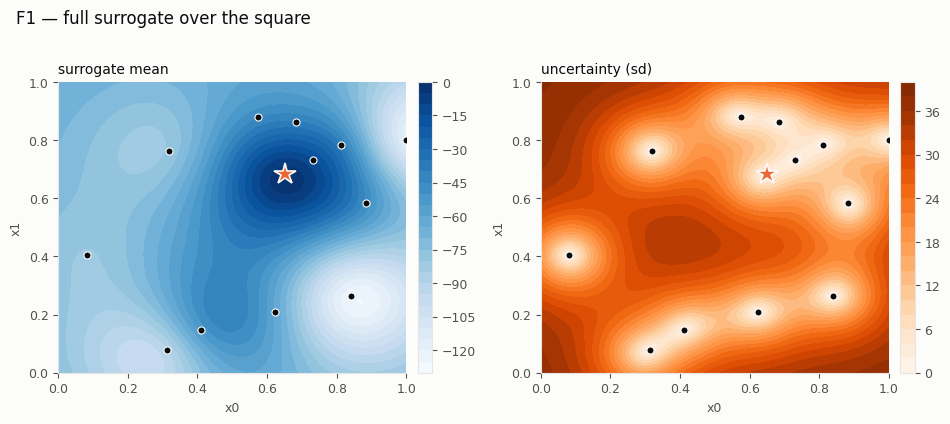

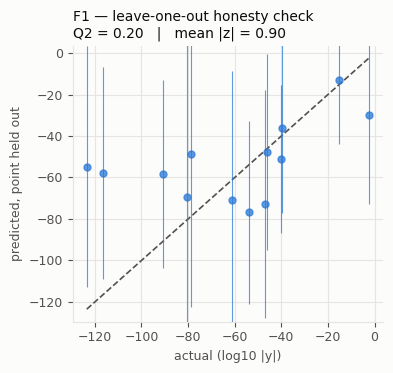

In [7]:
gp1 = report(1)

## Function 2

FUNCTION 2   dim=2   n=13 (10 initial + 3 trials)
  modelling y;  best = 0.611205  at  [0.702637 0.926564]
  raw best y = 0.611205
  kernel: 0.976**2 * Matern(length_scale=[0.0559, 10], nu=2.5) + WhiteKernel(noise_level=0.0149)
  noise sd = 0.1222  vs  output sd = 0.2432   ->  noise is 50% of the signal


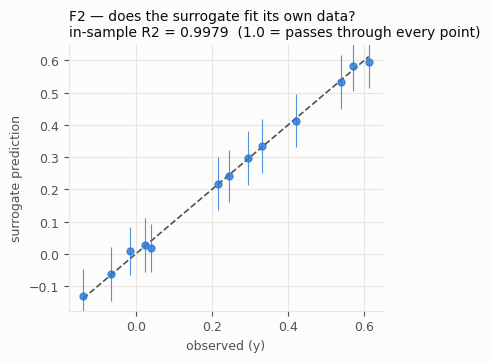

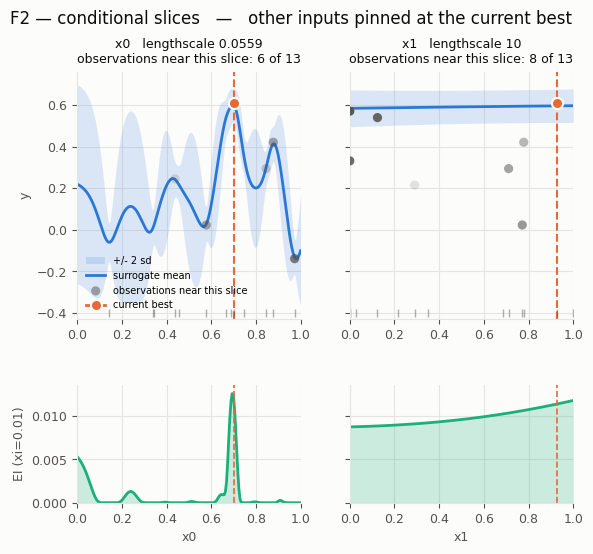

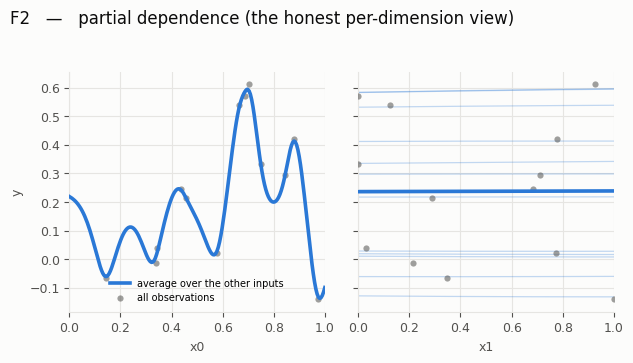

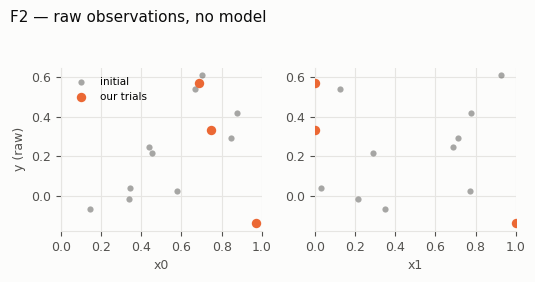

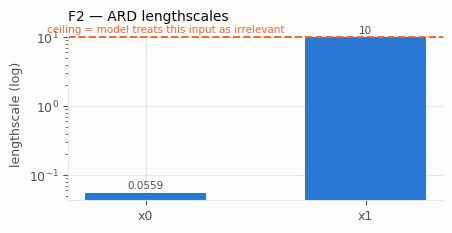

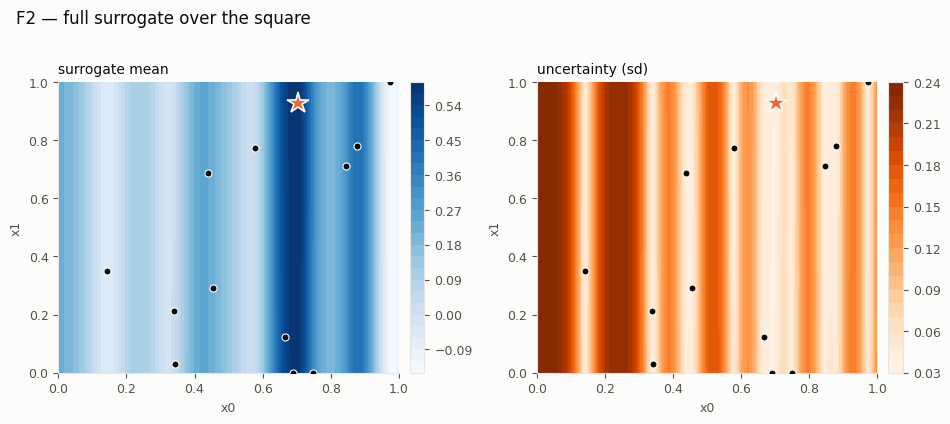

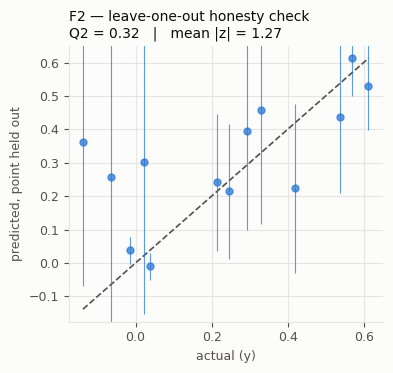

In [8]:
gp2 = report(2)

## Function 3

FUNCTION 3   dim=3   n=18 (15 initial + 3 trials)
  modelling y;  best = -0.0255336  at  [0.999999 0.598179 0.859784]
  raw best y = -0.0255336
  kernel: 1.44**2 * Matern(length_scale=[10, 10, 0.0926], nu=2.5) + WhiteKernel(noise_level=0.0158)
  noise sd = 0.1256  vs  output sd = 0.08158   ->  noise is 154% of the signal


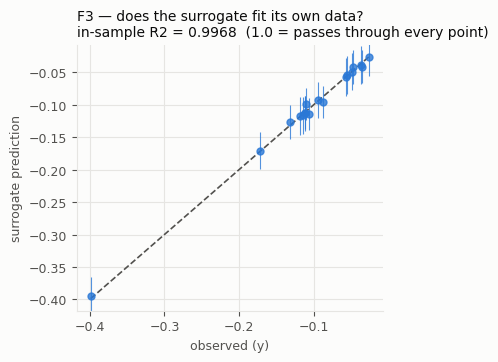

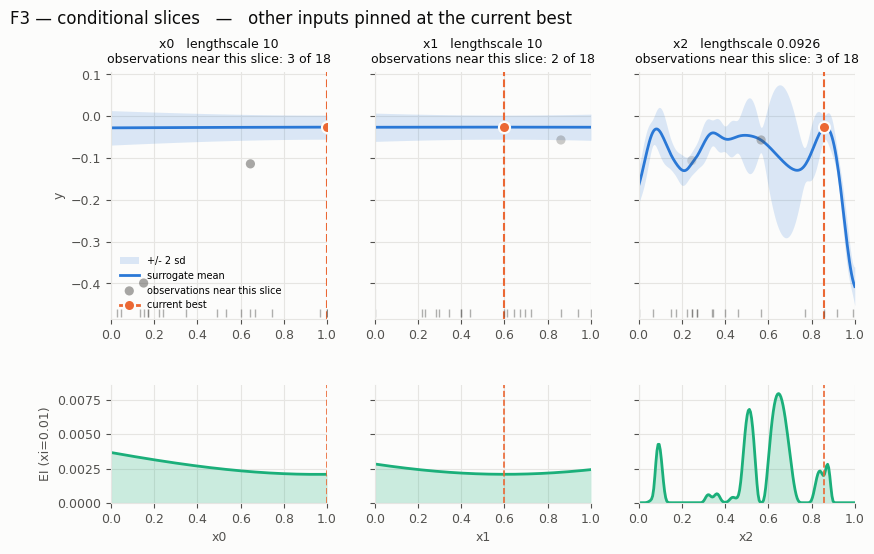

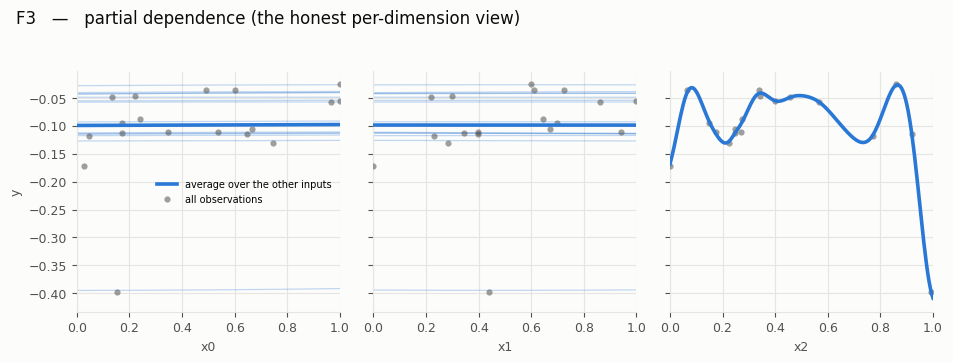

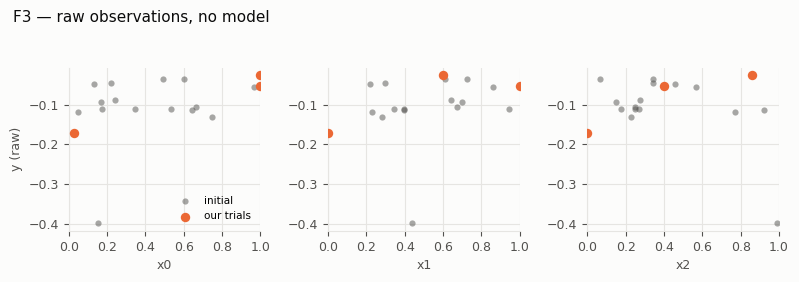

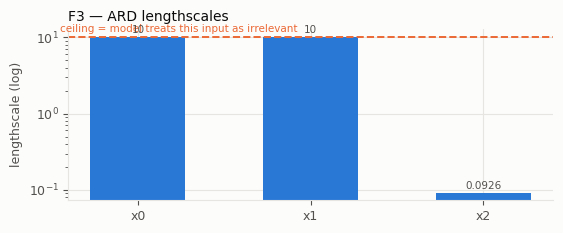

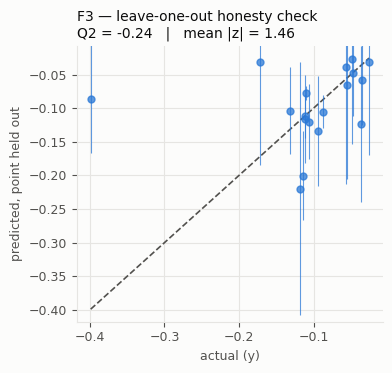

In [9]:
gp3 = report(3)

## Function 4

FUNCTION 4   dim=4   n=32 (30 initial + 2 trials)
  modelling y;  best = 0.523514  at  [0.407583 0.411177 0.347308 0.432592]
  raw best y = 0.523514
  kernel: 2.59**2 * Matern(length_scale=[1.43, 1.3, 1.26, 1.29], nu=2.5) + WhiteKernel(noise_level=0.0013)
  noise sd = 0.03602  vs  output sd = 7.872   ->  noise is 0% of the signal


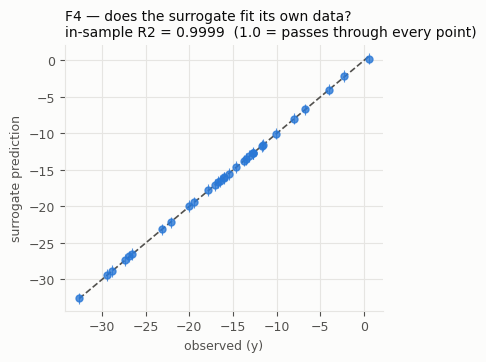

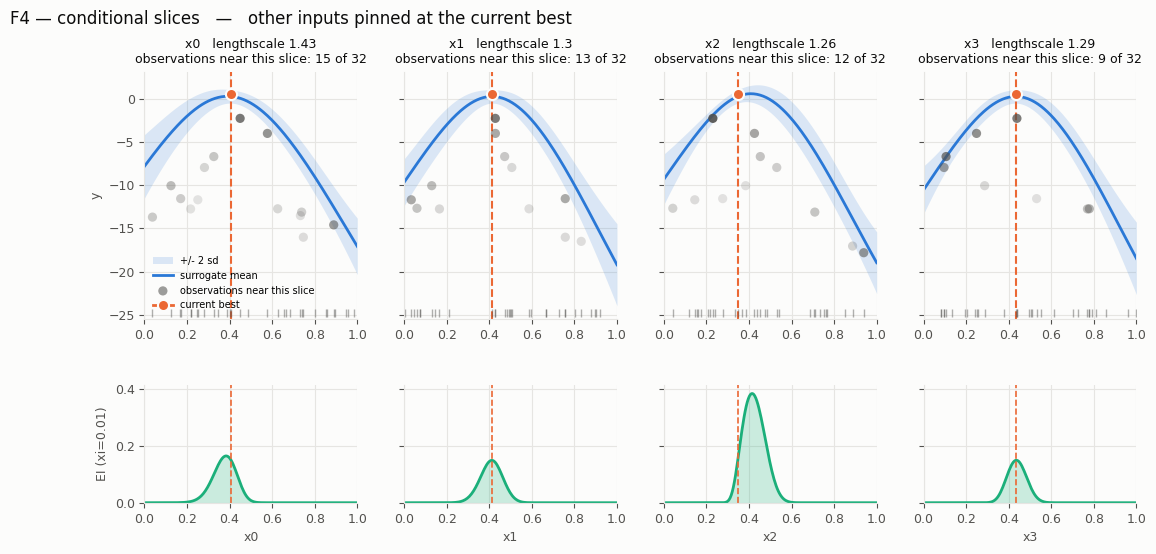

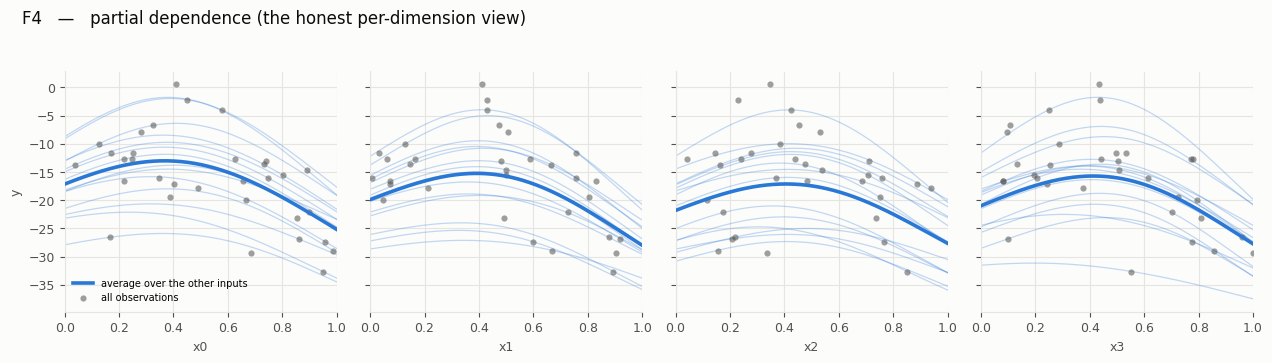

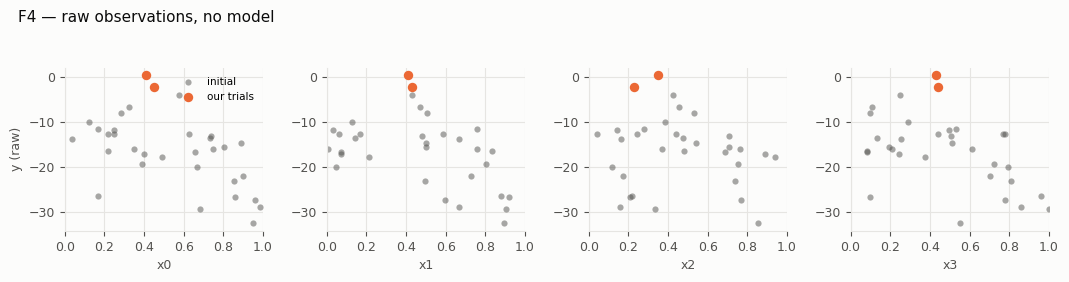

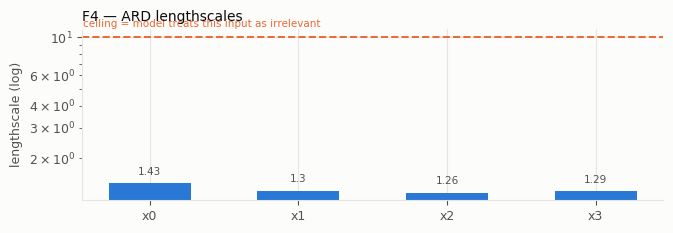

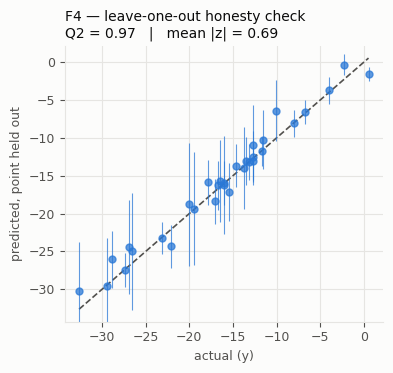

In [10]:
gp4 = report(4)

## Function 5

FUNCTION 5   dim=4   n=23 (20 initial + 3 trials)
  modelling log y;  best = 6.99289  at  [0.224189 0.84648  0.879484 0.878516]
  raw best y = 1088.86
  kernel: 1.85**2 * Matern(length_scale=[1.54, 0.489, 0.752, 0.66], nu=2.5) + WhiteKernel(noise_level=1e-06)
  noise sd = 0.001  vs  output sd = 1.95   ->  noise is 0% of the signal


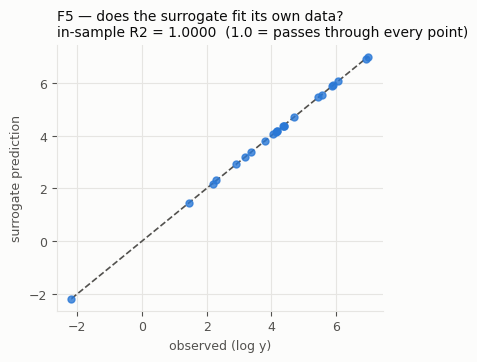

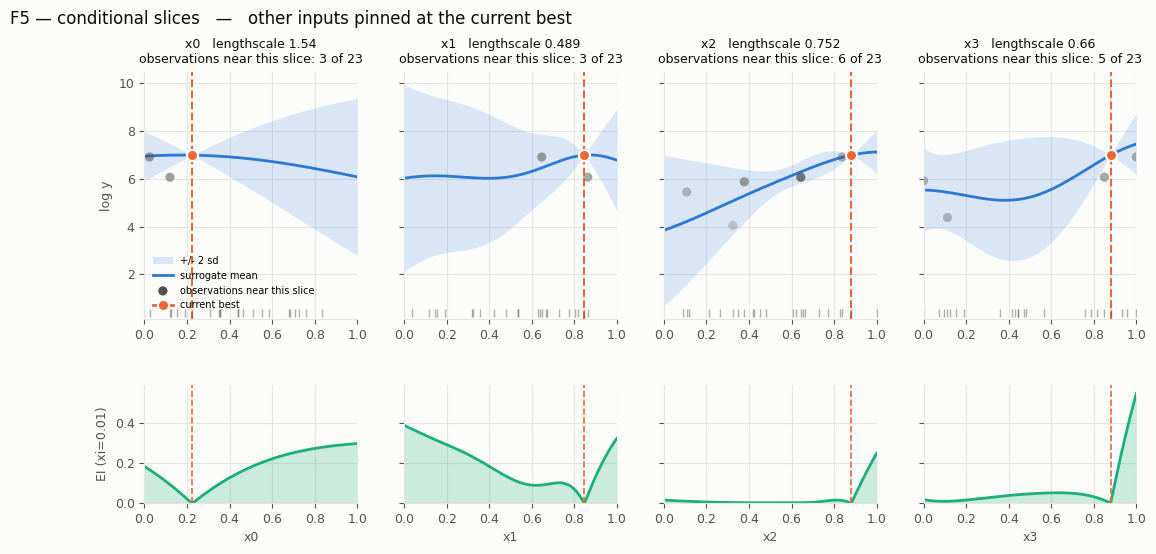

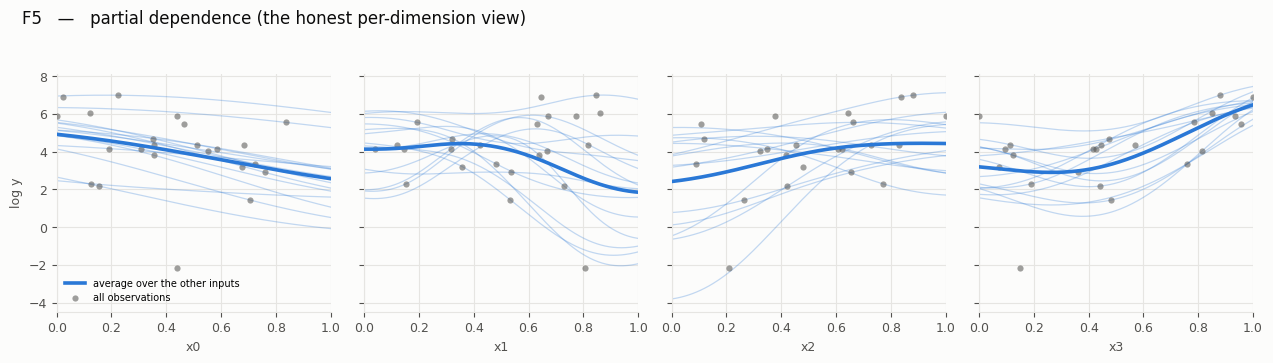

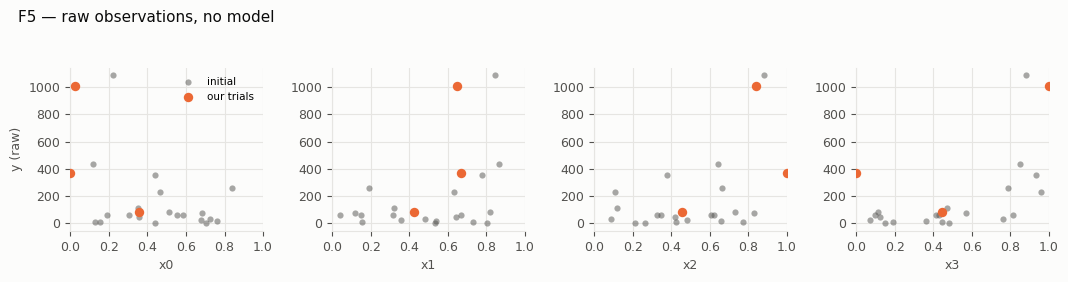

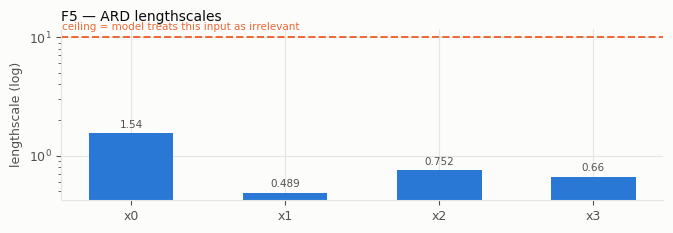

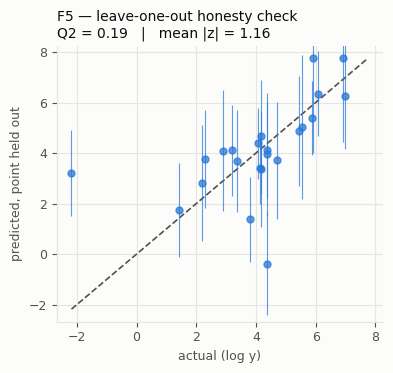

In [11]:
gp5 = report(5)

## Function 6

FUNCTION 6   dim=5   n=23 (20 initial + 3 trials)
  modelling y;  best = -0.649907  at  [4.22422e-01 1.43514e-01 8.01323e-01 9.99999e-01 1.00000e-06]
  raw best y = -0.649907
  kernel: 1.2**2 * Matern(length_scale=[10, 0.469, 0.819, 0.978, 0.462], nu=2.5) + WhiteKernel(noise_level=1e-06)
  noise sd = 0.001  vs  output sd = 0.4905   ->  noise is 0% of the signal


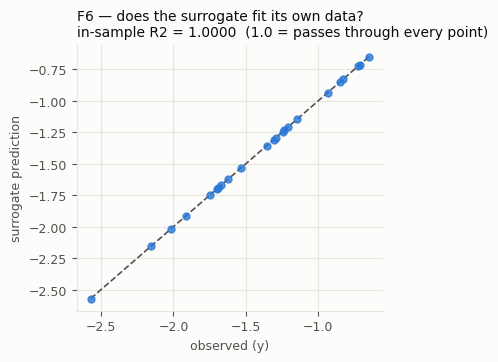

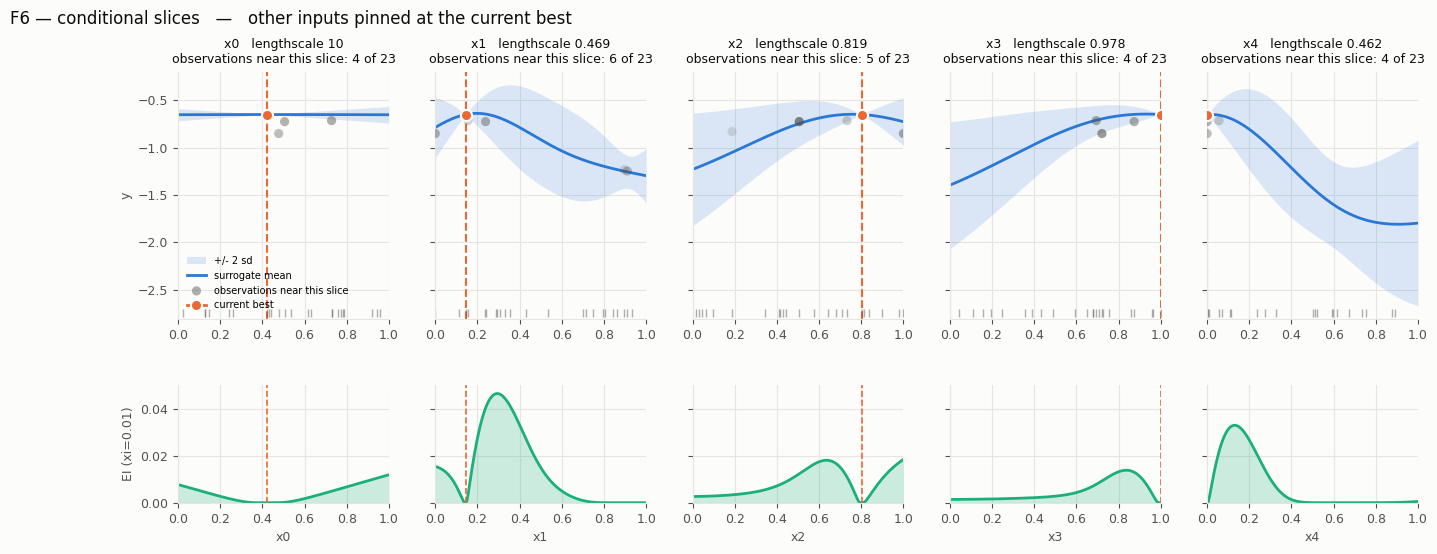

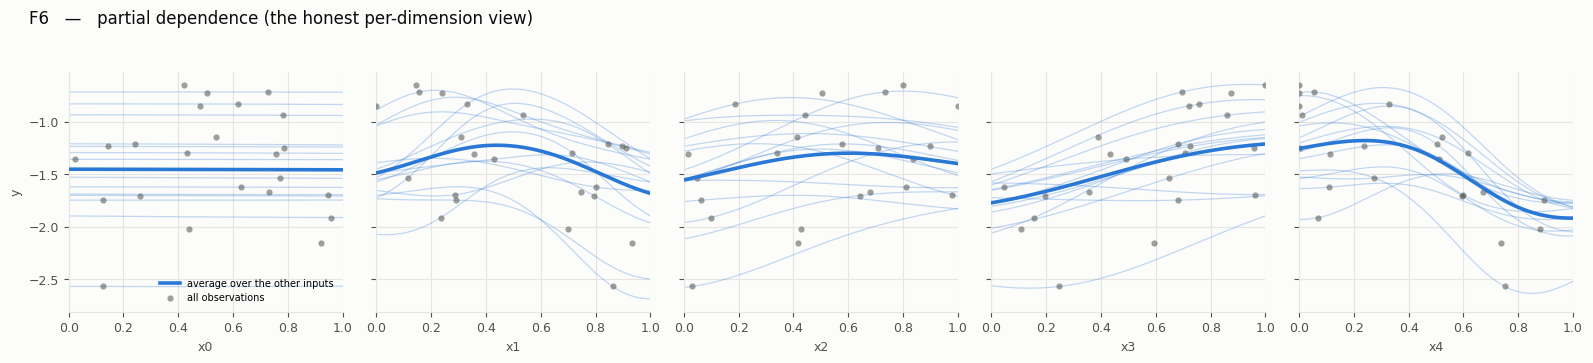

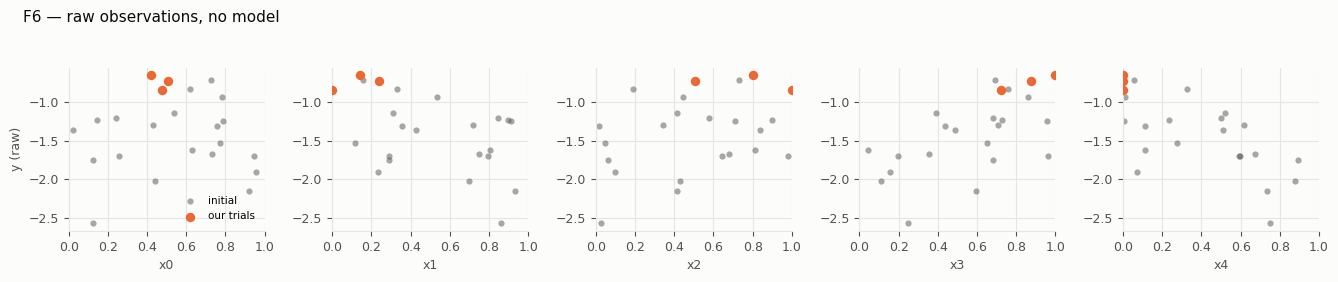

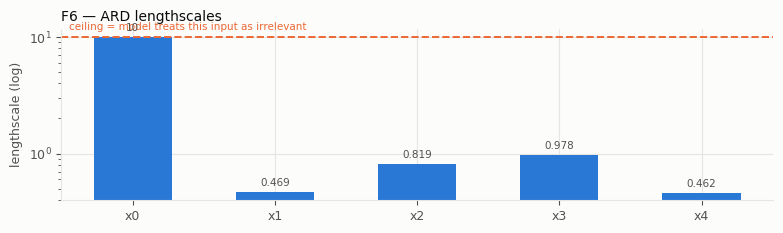

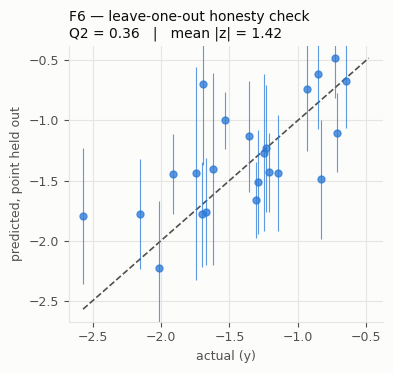

In [12]:
gp6 = report(6)

## Function 7

FUNCTION 7   dim=6   n=33 (30 initial + 3 trials)
  modelling y;  best = 2.40634  at  [1.00000e-06 1.84614e-01 4.48347e-01 2.14362e-01 3.73715e-01 7.49975e-01]
  raw best y = 2.40634
  kernel: 0.878**2 * Matern(length_scale=[0.618, 0.423, 10, 0.227, 0.233, 0.433], nu=2.5) + WhiteKernel(noise_level=1e-06)
  noise sd = 0.001  vs  output sd = 0.5136   ->  noise is 0% of the signal


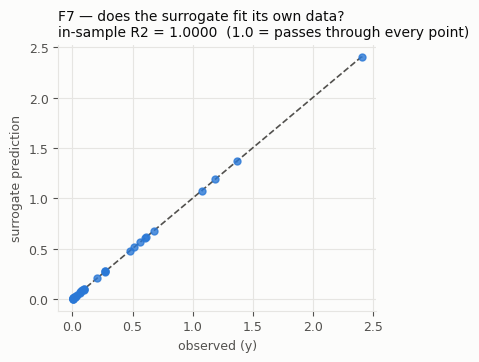

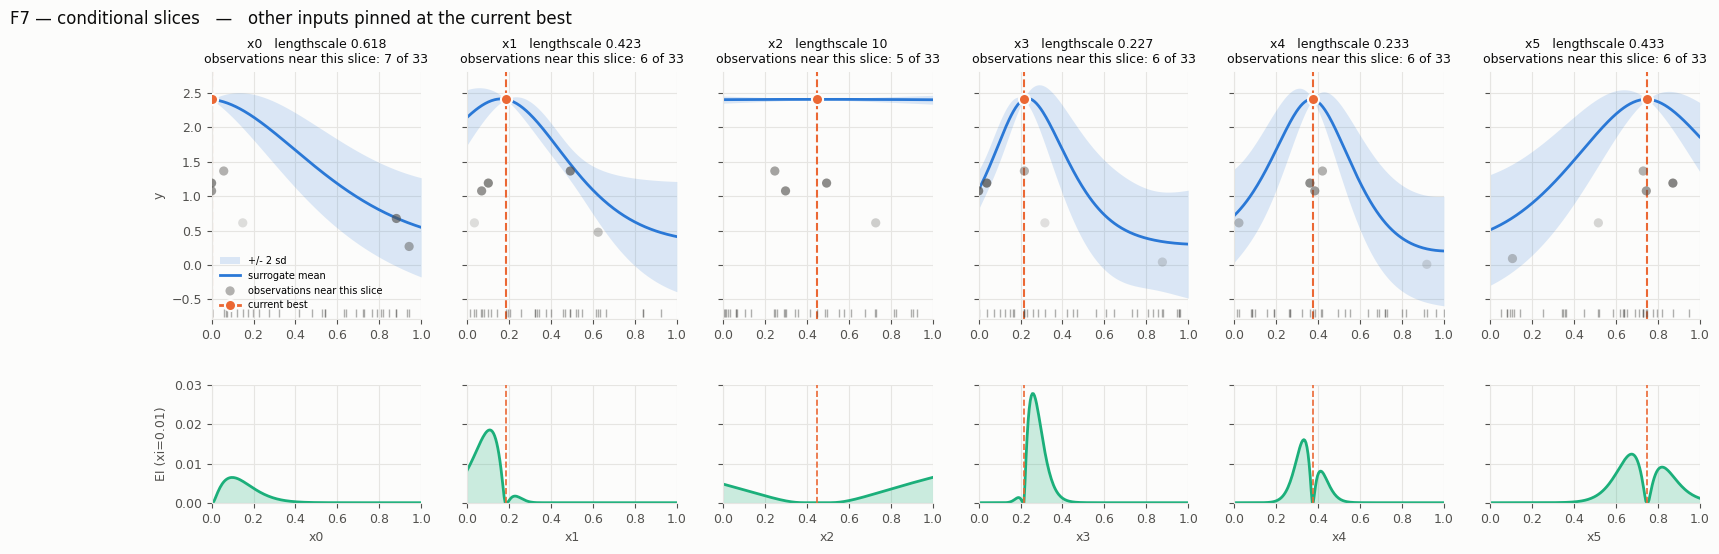

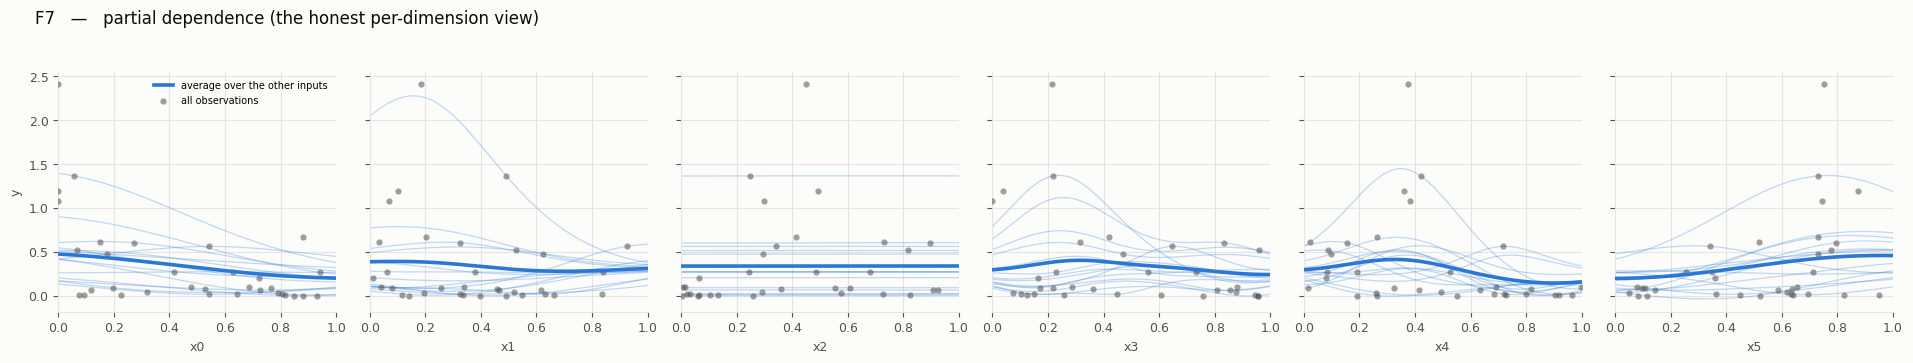

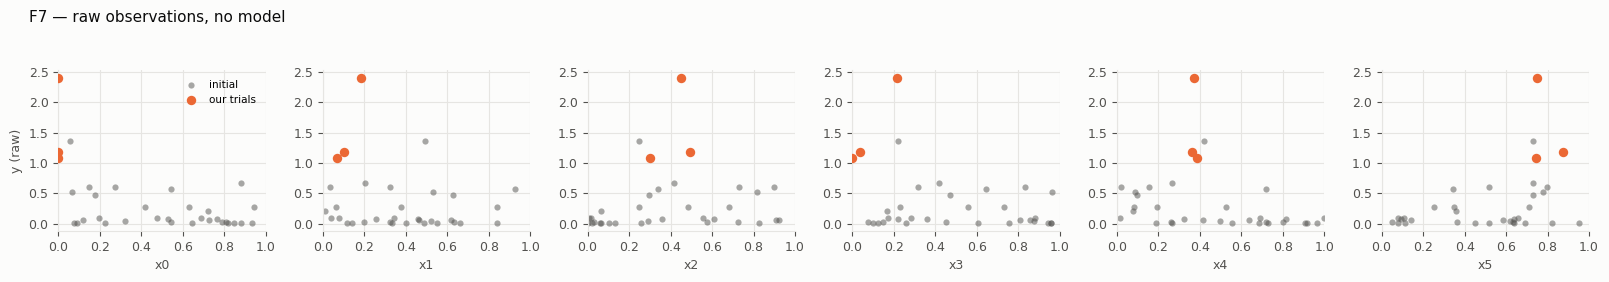

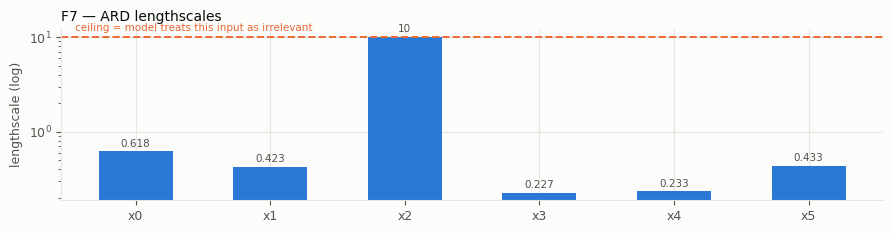

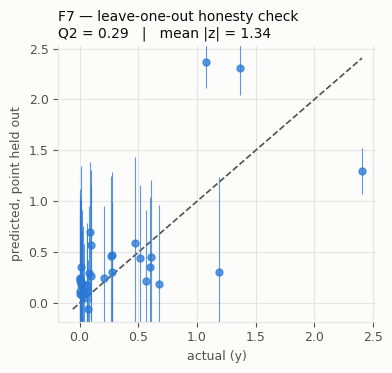

In [13]:
gp7 = report(7)

## Function 8

FUNCTION 8   dim=8   n=43 (40 initial + 3 trials)
  modelling y;  best = 9.87426  at  [1.00000e-06 1.00000e-06 2.00348e-01 1.00000e-06 6.03935e-01 6.01055e-01
 2.88307e-01 6.93085e-01]
  raw best y = 9.87426
  kernel: 3.25**2 * Matern(length_scale=[3.08, 4.32, 2.28, 8.96, 10, 4.61, 2.99, 10], nu=2.5) + WhiteKernel(noise_level=1e-06)
  noise sd = 0.001  vs  output sd = 1.045   ->  noise is 0% of the signal


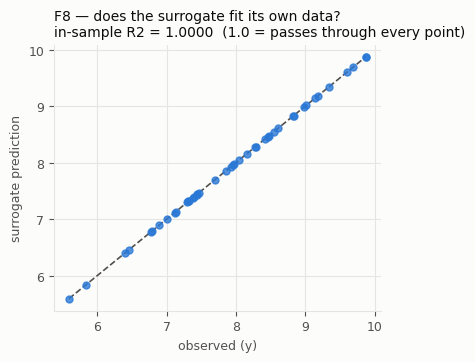

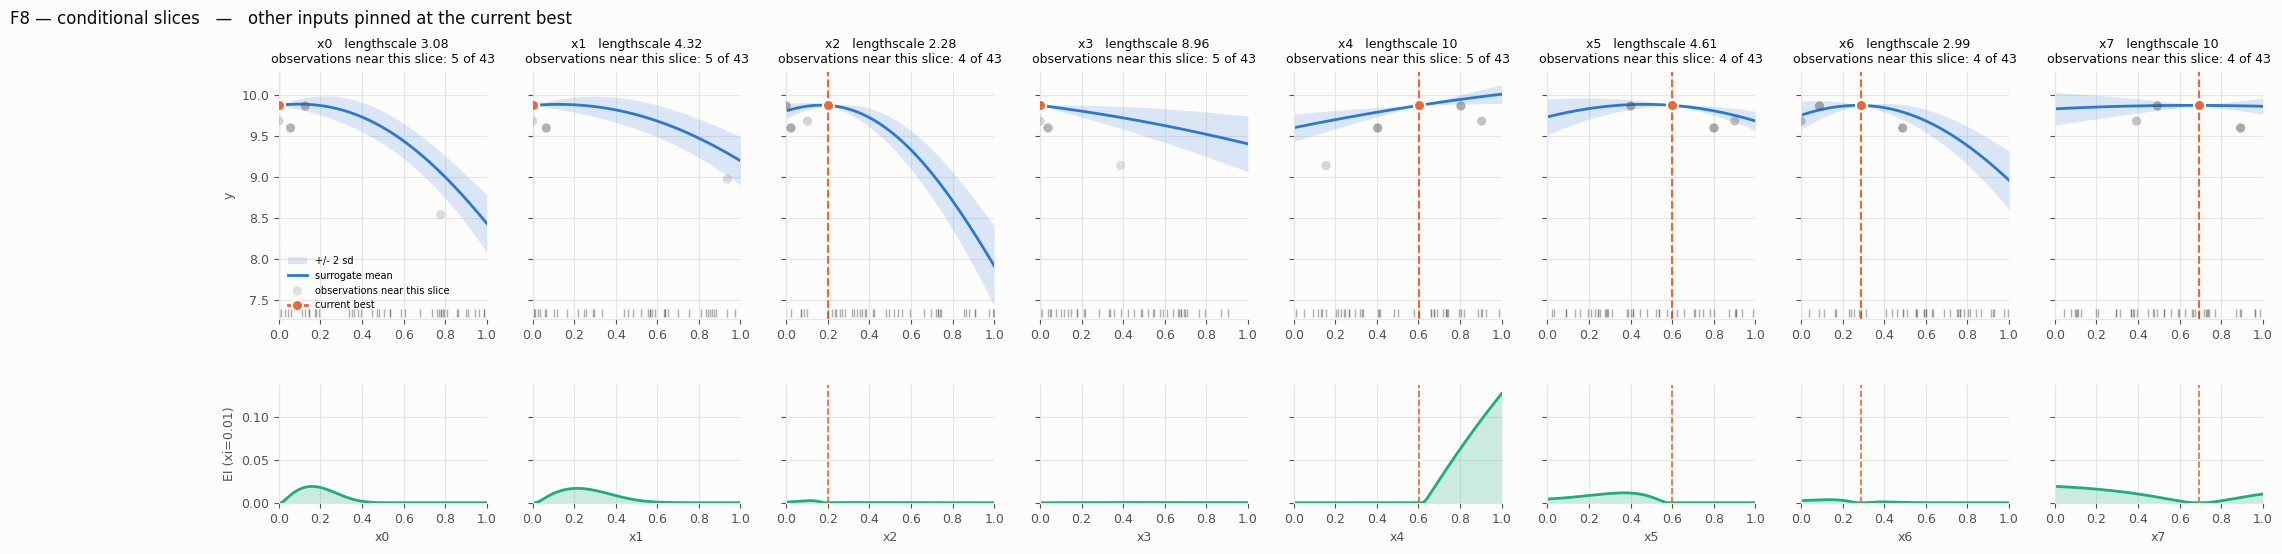

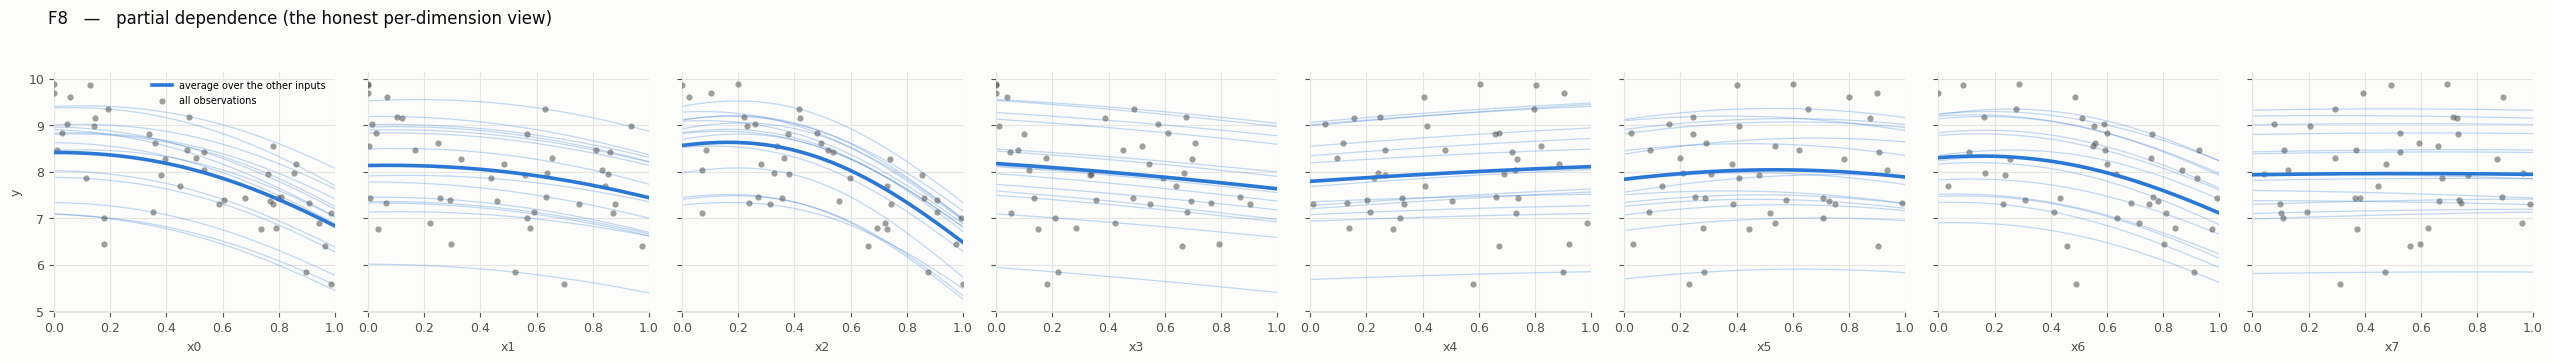

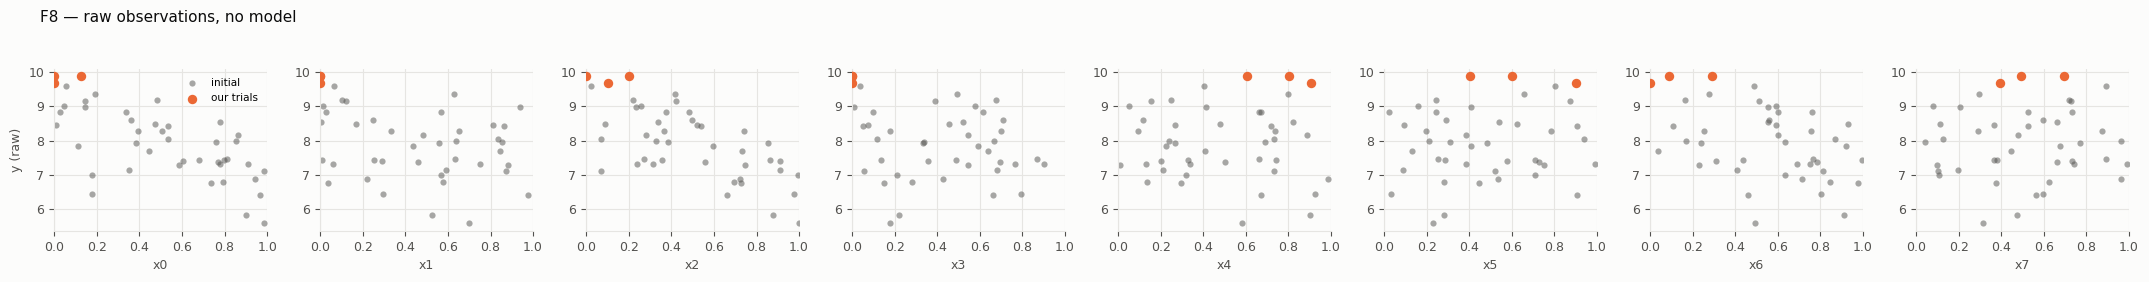

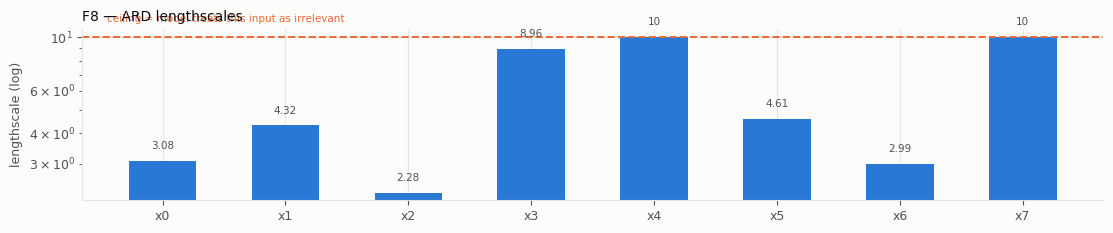

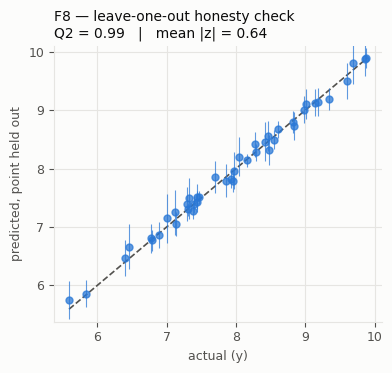

In [14]:
gp8 = report(8)

## Scoreboard — where the surrogate can be trusted

,function,n,dim,in_sample_R2,LOO_Q2,mean_abs_z
0,F1,13,2,1.0000,0.197,0.90
1,F2,13,2,0.9979,0.316,1.27
2,F3,18,3,0.9968,-0.242,1.46
3,F4,32,4,0.9999,0.967,0.69
4,F5,23,4,1.0000,0.190,1.16
5,F6,23,5,1.0000,0.358,1.42
6,F7,33,6,1.0000,0.290,1.34
7,F8,43,8,1.0000,0.991,0.64


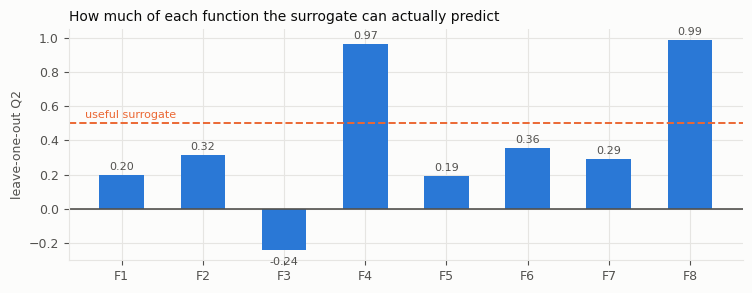

In [15]:
rows = []
for i in range(1, 9):
    X, y, _ = load(i)
    yy, label = transform(i, y)
    gp = fit_gp(X, yy, random_state=RANDOM_STATE)
    mu = gp.predict(X)
    r2 = 1 - np.sum((yy - mu) ** 2) / np.sum((yy - yy.mean()) ** 2)

    n = len(yy); pred = np.empty(n); sd = np.empty(n)
    for k in range(n):
        m = np.ones(n, bool); m[k] = False
        g = fit_gp(X[m], yy[m], n_restarts_optimizer=LOO_RESTARTS,
                   random_state=RANDOM_STATE)
        pp, ss = g.predict(X[k].reshape(1, -1), return_std=True)
        pred[k], sd[k] = pp[0], ss[0]
    q2 = 1 - np.sum((yy - pred) ** 2) / np.sum((yy - yy.mean()) ** 2)
    z = np.mean(np.abs((yy - pred) / np.maximum(sd, 1e-12)))
    rows.append({"function": f"F{i}", "n": n, "dim": X.shape[1],
                 "in_sample_R2": round(r2, 4), "LOO_Q2": round(q2, 3),
                 "mean_abs_z": round(z, 2)})

score = pd.DataFrame(rows)
display(score)

fig, ax = plt.subplots(figsize=(7.6, 3.0))
ax.bar(score.function, score.LOO_Q2, color=MEAN, width=0.55, zorder=2)
ax.axhline(0.0, color=INK2, lw=1.2)
ax.axhline(0.5, color=MARK, lw=1.4, ls="--")
ax.text(-0.45, 0.53, "useful surrogate", color=MARK, fontsize=8, ha="left")
ax.set_ylabel("leave-one-out Q2")
ax.set_title("How much of each function the surrogate can actually predict", loc="left")
for j, v in enumerate(score.LOO_Q2):
    ax.text(j, v + (0.03 if v >= 0 else -0.09), f"{v:.2f}", ha="center",
            fontsize=8, color=INK2)
plt.tight_layout(); plt.show()

## How to read these

**In-sample R² near 1 with a low leave-one-out Q² is not a contradiction.** The
first says the model interpolates the points it has seen; the second says it cannot
predict a point it has not seen. With few observations spread through a large space
both are true at once, and the second is the one that decides whether a proposal is
worth anything.

**Conditional slices reading "near slice: 0" are the important ones.** They mean the
curve is pure extrapolation along that line — nothing has been measured anywhere
near it. The band width is then the only honest signal, and a proposal placed there
is a guess wearing an optimum's clothes.

**Spread in the partial-dependence lines is interaction.** Roughly parallel lines
mean the input acts on its own and the average curve is a fair summary of it. Lines
that cross and change shape mean the input's effect depends on the others, so no
one-dimensional picture can be trusted and that function wants local search around
a known-good point rather than global reasoning.

**Compare the ARD bars against the raw marginals.** A bar at the ceiling means the
model believes that input is irrelevant. If the raw scatter for it clearly trends,
the kernel fit found a bad optimum and the verdict should not be acted on — that
mistake has already cost trials on one function.
